# Chapter 14: Charts With matplotlib

The programs from Chapter 14 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## Line Charts: Change Over Time

`line_chart.py`

Saved line_chart.png


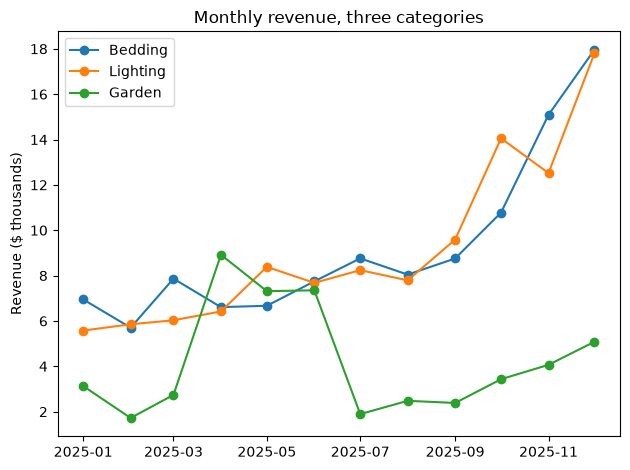

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

orders = pd.read_csv("../data/orders.csv", parse_dates=["order_date"])
orders["revenue"] = orders["quantity"] * orders["unit_price"]
monthly = (
    orders.set_index("order_date")
    .groupby("category")["revenue"]
    .resample("MS")
    .sum()
    .unstack(level=0)
)

fig, ax = plt.subplots()
for category in ["Bedding", "Lighting", "Garden"]:
    ax.plot(
        monthly.index, monthly[category] / 1000, marker="o", label=category
    )
ax.set_title("Monthly revenue, three categories")
ax.set_ylabel("Revenue ($ thousands)")
ax.legend()
fig.tight_layout()
fig.savefig("line_chart.png")
print("Saved line_chart.png")

## Bar Charts: Comparing Categories

`bar_chart.py`

Saved bar_chart.png


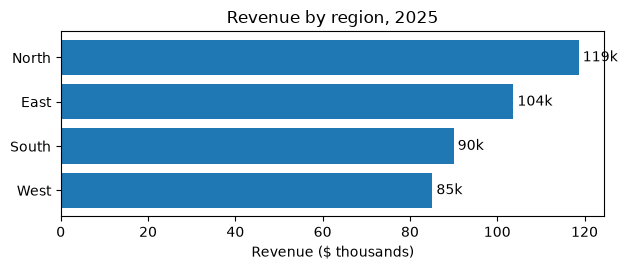

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

orders = pd.read_csv("../data/orders.csv")
orders["revenue"] = orders["quantity"] * orders["unit_price"]
by_region = orders.groupby("region")["revenue"].sum().sort_values()

fig, ax = plt.subplots(figsize=(6.4, 2.8))
bars = ax.barh(by_region.index, by_region / 1000)
ax.bar_label(bars, fmt="%.0fk", padding=3)
ax.set_title("Revenue by region, 2025")
ax.set_xlabel("Revenue ($ thousands)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("bar_chart.png")
print("Saved bar_chart.png")

## Histograms: How Values Are Spread

`histogram.py`

Saved histogram.png


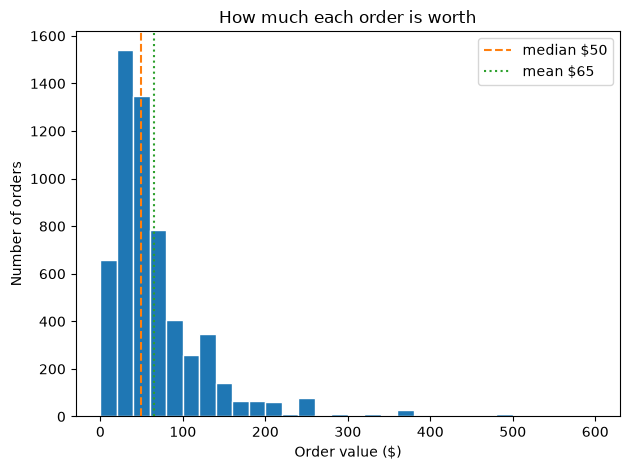

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

orders = pd.read_csv("../data/orders.csv")
value = orders["quantity"] * orders["unit_price"] * (1 - orders["discount"])

fig, ax = plt.subplots()
ax.hist(value, bins=range(0, 620, 20), edgecolor="white")
ax.axvline(
    value.median(),
    color="C1",
    linestyle="--",
    label=f"median ${value.median():.0f}",
)
ax.axvline(
    value.mean(),
    color="C2",
    linestyle=":",
    label=f"mean ${value.mean():.0f}",
)
ax.set_title("How much each order is worth")
ax.set_xlabel("Order value ($)")
ax.set_ylabel("Number of orders")
ax.legend()
fig.tight_layout()
fig.savefig("histogram.png")
print("Saved histogram.png")

## Scatter Plots: Two Measures Together

`scatter.py`

Saved scatter.png


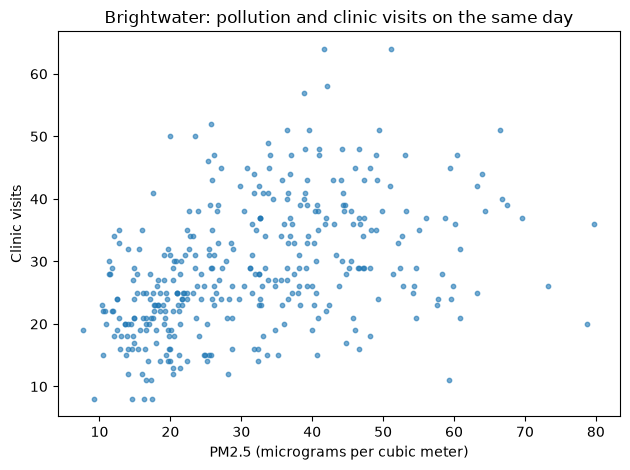

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

air = pd.read_csv("../data/air_quality.csv", parse_dates=["date"])
visits = pd.read_csv("../data/clinic_visits.csv", parse_dates=["date"])
city = air.merge(visits, on=["date", "city"]).query("city == 'Brightwater'")

fig, ax = plt.subplots()
ax.scatter(city["pm25"], city["visits"], s=10, alpha=0.6)
ax.set_title("Brightwater: pollution and clinic visits on the same day")
ax.set_xlabel("PM2.5 (micrograms per cubic meter)")
ax.set_ylabel("Clinic visits")
fig.tight_layout()
fig.savefig("scatter.png")
print("Saved scatter.png")